# Logistic Regression — Step-by-Step Practical Notebook

**A beginner-friendly practical that follows the trainer presentation.**

We will use two connected examples:

1. **Student Pass/Fail:** Calculate a linear score, apply Sigmoid, choose a class, and understand Log Loss.
2. **Iris flowers:** Train a real binary Logistic Regression model, evaluate it, and tune it using cross-validation and `GridSearchCV`.

### What you'll learn
- Why Logistic Regression is used for classification rather than predicting a continuous number.
- How `z = mx + c` becomes a class probability using Sigmoid.
- What a classification threshold and decision boundary mean.
- How Log Loss measures the quality of predicted probabilities.
- How `fit`, `predict`, and `predict_proba` work in Scikit-learn.
- How to evaluate a model and tune `C` without leaking test-set information.

> **Scope:** No Logit terminology, Maximum Likelihood derivations, derivatives, or optimizer internals. The student-example coefficients below are **illustrative**, not fitted to the data.

**Requirements:** `numpy`, `pandas`, `matplotlib`, and `scikit-learn`. The Iris dataset is included with Scikit-learn; no internet connection or Kaggle download is required.

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    log_loss, roc_auc_score, RocCurveDisplay
)

pd.set_option("display.float_format", lambda v: f"{v:.3f}")
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Example A — Predict Pass or Fail

Suppose the input is **hours studied** (`x`) and the output is **Pass = 1 / Fail = 0**.

Unlike Linear Regression, we need a **probability between 0 and 1**.

Logistic Regression starts by calculating a linear score:

\[
z=mx+c
\]

For illustration, let `m = 1.5` and `c = -6`. These numbers are given only to explain prediction; the model will learn coefficients during actual training.

In [2]:
hours = 5
m = 1.5  # illustrative coefficient
c = -6   # illustrative intercept

z = m * hours + c
print(f"Hours studied = {hours}")
print(f"Linear score z = {m} × {hours} + ({c}) = {z:.2f}")

Hours studied = 5
Linear score z = 1.5 × 5 + (-6) = 1.50


## 3. Apply the Sigmoid function

Sigmoid converts *any* linear score into a probability:

\[
p=\frac{1}{1+e^{-z}}
\]

For our example, `z = 1.5`, so the probability of **Pass (class 1)** is about **0.818 (81.8%)**.

In [3]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

p_pass = sigmoid(z)
print(f"Probability of passing: {p_pass:.4f} ({p_pass:.2%})")
print(f"Probability of failing: {1 - p_pass:.4f} ({1-p_pass:.2%})")

Probability of passing: 0.8176 (81.76%)
Probability of failing: 0.1824 (18.24%)


### Visualize Sigmoid — every input score maps to a probability between 0 and 1

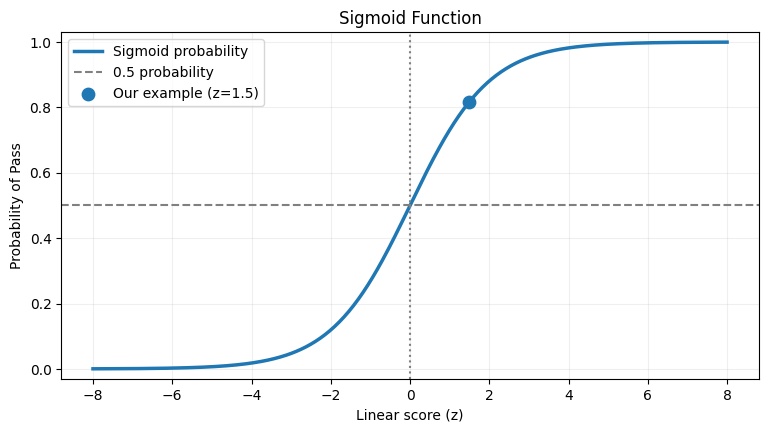

In [4]:
z_values = np.linspace(-8, 8, 400)
plt.figure(figsize=(9, 4.5))
plt.plot(z_values, sigmoid(z_values), lw=2.5, label="Sigmoid probability")
plt.axhline(0.5, color="gray", ls="--", label="0.5 probability")
plt.axvline(0, color="gray", ls=":")
plt.scatter([1.5], [sigmoid(1.5)], s=80, zorder=5, label="Our example (z=1.5)")
plt.xlabel("Linear score (z)")
plt.ylabel("Probability of Pass")
plt.title("Sigmoid Function")
plt.ylim(-0.03, 1.03)
plt.grid(alpha=0.2)
plt.legend()
plt.show()

## 4. Turn probability into Pass / Fail

For this example, choose a **classification threshold of 0.5**:

- Probability **≥ 0.5** → predict **Pass (1)**
- Probability **< 0.5** → predict **Fail (0)**

The threshold is applied **after** the probability is calculated.

In [5]:
threshold = 0.5
predicted_class = int(p_pass >= threshold)
print(f"Probability: {p_pass:.3f}")
print(f"Threshold:   {threshold:.2f}")
print(f"Prediction:  {predicted_class} ({'Pass' if predicted_class else 'Fail'})")

Probability: 0.818
Threshold:   0.50
Prediction:  1 (Pass)


## 5. Decision boundary

The **decision boundary** is where the probability equals the chosen threshold.

For a threshold of 0.5, Sigmoid returns 0.5 when `z = 0`.

For our illustrative equation `z = 1.5 × hours − 6`:

\[
0=1.5x-6\quad\Rightarrow\quad x=4
\]

This is the boundary for **this illustrative model**, not a rule about students in general.

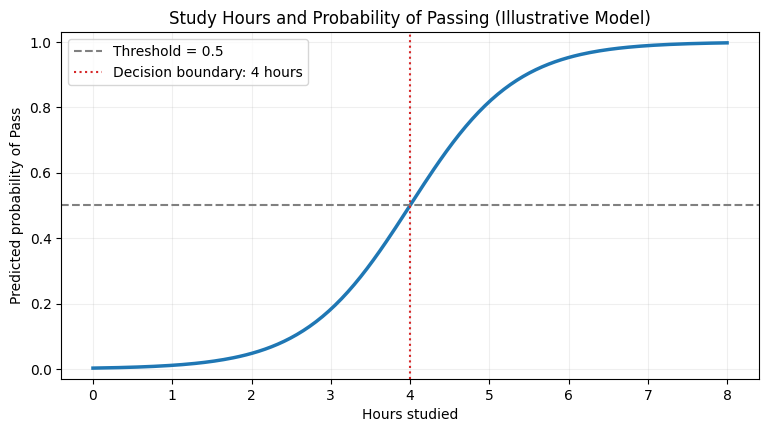

,Hours,Score z,P(Pass),Predicted class
0,1,-4.500,0.011,0
1,2,-3.000,0.047,0
2,3,-1.500,0.182,0
3,4,0.000,0.500,1
4,5,1.500,0.818,1
5,6,3.000,0.953,1


In [6]:
study_hours = np.linspace(0, 8, 200)
probabilities = sigmoid(m * study_hours + c)

plt.figure(figsize=(9, 4.5))
plt.plot(study_hours, probabilities, lw=2.5)
plt.axhline(0.5, linestyle="--", color="gray", label="Threshold = 0.5")
plt.axvline(4, linestyle=":", color="tab:red", label="Decision boundary: 4 hours")
plt.xlabel("Hours studied")
plt.ylabel("Predicted probability of Pass")
plt.title("Study Hours and Probability of Passing (Illustrative Model)")
plt.ylim(-0.03, 1.03)
plt.grid(alpha=0.2)
plt.legend()
plt.show()

comparison = pd.DataFrame({"Hours": np.arange(1, 7)})
comparison["Score z"] = m * comparison["Hours"] + c
comparison["P(Pass)"] = sigmoid(comparison["Score z"])
comparison["Predicted class"] = (comparison["P(Pass)"] >= 0.5).astype(int)
display(comparison)

## 6. What is Log Loss?

**Log Loss measures how well our predicted probability agrees with the actual class.**

- If the actual result is **Pass (1)**, a high `P(Pass)` gives a low loss.
- If the actual result is **Fail (0)**, a low `P(Pass)` gives a low loss.
- A confidently wrong prediction gets a **large loss**.

For **one observation**:

\[
L=-[y\ln(p)+(1-y)\ln(1-p)]
\]

You do **not** need to derive this formula. Focus on what its outputs mean.

In [7]:
cases = pd.DataFrame({
    "Actual class": [1, 1, 0, 0],
    "Predicted P(Pass)": [0.90, 0.10, 0.10, 0.90],
})

# Choose the probability of the actual result, then take negative log.
cases["P(actual result)"] = np.where(
    cases["Actual class"] == 1,
    cases["Predicted P(Pass)"],
    1 - cases["Predicted P(Pass)"]
)
cases["Log Loss"] = -np.log(cases["P(actual result)"])
print("Smaller Log Loss means the predicted probability fits the actual result better.")
display(cases)

Smaller Log Loss means the predicted probability fits the actual result better.


,Actual class,Predicted P(Pass),P(actual result),Log Loss
0,1,0.900,0.900,0.105
1,1,0.100,0.100,2.303
2,0,0.100,0.900,0.105
3,0,0.900,0.100,2.303


### Log Loss across several students

For a dataset, the model considers the **average loss** across observations, not just one student.

We can calculate that with Scikit-learn's `log_loss` function.

In [8]:
actual = np.array([1, 0, 1])
predicted_p_pass = np.array([0.8, 0.3, 0.6])

average_loss = log_loss(actual, predicted_p_pass, labels=[0, 1])
print(f"Average Log Loss: {average_loss:.3f}")
print("During training, the model seeks coefficients that reduce its training objective.")

Average Log Loss: 0.364
During training, the model seeks coefficients that reduce its training objective.


## 7. How the model learns — conceptual view

We used `m = 1.5` and `c = -6` just to understand prediction. In actual training, the model **learns** coefficients from the data.

1. Begin with initial coefficient values.
2. Calculate each student's score and probability.
3. Compare the probabilities with the actual Pass/Fail outcomes using Log Loss.
4. Adjust coefficients to improve the fit.
5. Repeat the adjustment process.

This is the **Gradient Descent intuition**: keep moving toward a lower loss. We will not calculate derivatives or manually implement the updates.

Below we fit a small model to actual example labels. Its learned coefficients **will not be the same as** the illustrative coefficients.

In [9]:
X_small = np.array([[1], [2], [3], [4], [5]])
y_small = np.array([0, 0, 0, 1, 1])

small_model = LogisticRegression()
small_model.fit(X_small, y_small)

print("Learned coefficient:", small_model.coef_[0, 0])
print("Learned intercept:  ", small_model.intercept_[0])

new_student = np.array([[5]])
print("P(Pass) for 5 hours:", small_model.predict_proba(new_student)[0, 1])
print("Predicted class:     ", small_model.predict(new_student)[0])

# This tiny dataset is for demonstrating fit, not rigorous evaluation.

Learned coefficient: 1.0470438047457902
Learned intercept:   -3.7481774320466803
P(Pass) for 5 hours: 0.8156338164057728
Predicted class:      1


---
# Example B — Real Binary Classification on Iris

The Scikit-learn **Iris** dataset contains measurements of flowers from three species.

To keep this lesson focused on **binary Logistic Regression**, we use only:

- **Versicolor = 0**
- **Virginica = 1**

We use two input features to make the decision boundary easy to visualize:

- Sepal length (cm)
- Sepal width (cm)

This dataset is **built into Scikit-learn**.

## 8. Load and inspect the data

In [10]:
iris = load_iris(as_frame=True)
full_df = iris.frame

# Keep only Versicolor (target=1) and Virginica (target=2)
mask = full_df["target"].isin([1, 2])
df = full_df.loc[mask, ["sepal length (cm)", "sepal width (cm)", "target"]].copy()
df["target"] = (df["target"] == 2).astype(int)

X = df[["sepal length (cm)", "sepal width (cm)"]]
y = df["target"]

print("Shape of X:", X.shape)
print("Class counts: (0=Versicolor; 1=Virginica)")
print(y.value_counts().sort_index())
display(df.head())

Shape of X: (100, 2)
Class counts: (0=Versicolor; 1=Virginica)
target
0    50
1    50
Name: count, dtype: int64


,sepal length (cm),sepal width (cm),target
50,7.000,3.200,0
51,6.400,3.200,0
52,6.900,3.100,0
53,5.500,2.300,0
54,6.500,2.800,0


### Visualize the two classes

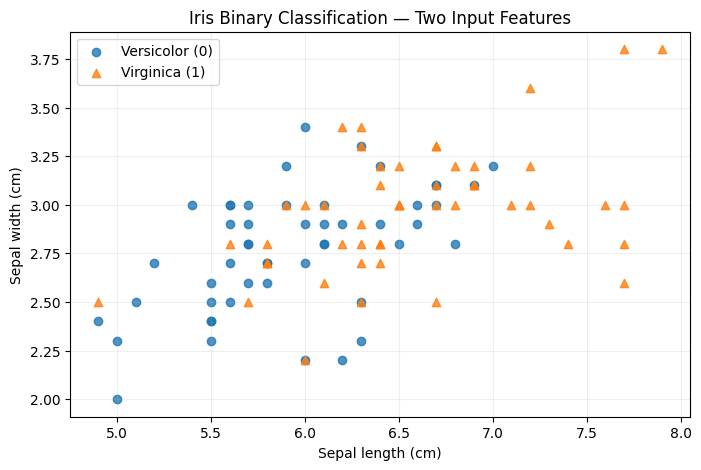

In [11]:
plt.figure(figsize=(8, 5))
for label, name, marker in [(0, "Versicolor (0)", "o"), (1, "Virginica (1)", "^")]:
    subset = df[df["target"] == label]
    plt.scatter(
        subset["sepal length (cm)"], subset["sepal width (cm)"],
        label=name, marker=marker, alpha=0.8
    )
plt.title("Iris Binary Classification — Two Input Features")
plt.xlabel("Sepal length (cm)")
plt.ylabel("Sepal width (cm)")
plt.grid(alpha=0.2)
plt.legend()
plt.show()

## 9. Split the data into training and test sets

- The **training set** is used to learn model coefficients.
- The **test set** is kept aside for a final evaluation.
- `stratify=y` preserves similar class proportions in both sets.
- `random_state=42` makes this split reproducible.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print(f"Training samples: {len(X_train)}")
print(f"Testing samples:  {len(X_test)}")
print("Train class counts:", y_train.value_counts().sort_index().to_dict())
print("Test class counts: ", y_test.value_counts().sort_index().to_dict())

Training samples: 75
Testing samples:  25
Train class counts: {0: 37, 1: 38}
Test class counts:  {0: 13, 1: 12}


## 10. Create and train the Logistic Regression model

Use a `Pipeline` for two steps:

1. `StandardScaler` learns how to scale the features from the **training data**.
2. `LogisticRegression` learns coefficients from the scaled features and labels.

The single line `model.fit(X_train, y_train)` runs both steps in order. The same learned scaling is applied automatically to test data and new data.

In [13]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(max_iter=1000)),
])

model.fit(X_train, y_train)
print("Model trained successfully.")
print("Learned coefficients (for scaled features):", model.named_steps["logreg"].coef_)
print("Learned intercept:", model.named_steps["logreg"].intercept_)

Model trained successfully.
Learned coefficients (for scaled features): [[1.07622668 0.51612639]]
Learned intercept: [0.04504536]


## 11. Predict classes and probabilities

- `predict_proba(...)` returns two probabilities per row: `P(class 0)` and `P(class 1)`.
- `predict(...)` returns the final class label.
- `decision_function(...)` returns the linear score *before* Sigmoid.

**Important:** The coefficients printed above belong to **scaled features**, because we used `StandardScaler`.

In [14]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]  # P(Virginica = class 1)

results = X_test.copy()
results["Actual class"] = y_test.to_numpy()
results["P(class 1)"] = y_prob
results["Predicted class"] = y_pred

display(results.head(10))

# Verify: Sigmoid(linear score) matches the model's class-1 probability.
first_score = model.decision_function(X_test.iloc[:1])[0]
first_probability = model.predict_proba(X_test.iloc[:1])[0, 1]
print(f"First flower linear score: {first_score:.4f}")
print(f"Sigmoid(score): {sigmoid(first_score):.4f}")
print(f"predict_proba:  {first_probability:.4f}")
assert np.isclose(sigmoid(first_score), first_probability)

,sepal length (cm),sepal width (cm),Actual class,P(class 1),Predicted class
135,7.700,3.000,1,0.919,1
113,5.700,2.500,1,0.154,0
106,4.900,2.500,1,0.046,0
85,6.000,3.400,0,0.566,1
103,6.300,2.900,1,0.486,0
134,6.100,2.600,1,0.294,0
91,6.100,3.000,0,0.445,0
116,6.500,3.000,1,0.609,1
119,6.000,2.200,1,0.155,0
101,5.800,2.700,1,0.230,0


First flower linear score: 2.4321
Sigmoid(score): 0.9192
predict_proba:  0.9192


## 12. Plot the learned decision boundary

With **two features**, the classification boundary is a **line** in the feature space.

Here the boundary separates the points where the model predicts class 0 from those where it predicts class 1 using the default **0.5 threshold**.

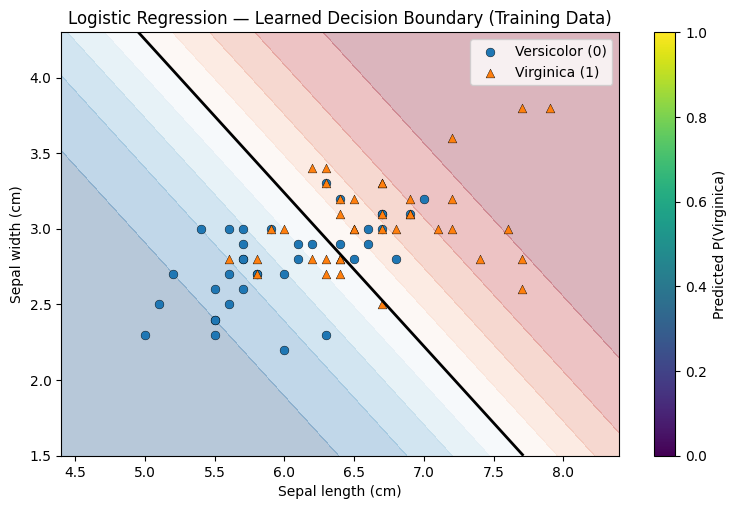

In [15]:
x_min, x_max = X["sepal length (cm)"].min() - 0.5, X["sepal length (cm)"].max() + 0.5
y_min, y_max = X["sepal width (cm)"].min() - 0.5, X["sepal width (cm)"].max() + 0.5
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)
mesh_df = pd.DataFrame({
    "sepal length (cm)": xx.ravel(),
    "sepal width (cm)": yy.ravel()
})
mesh_prob = model.predict_proba(mesh_df)[:, 1].reshape(xx.shape)

plt.figure(figsize=(9, 5.5))
plt.contourf(xx, yy, mesh_prob, levels=np.linspace(0, 1, 11), cmap="RdBu_r", alpha=0.3)
plt.contour(xx, yy, mesh_prob, levels=[0.5], colors="black", linewidths=2)
for label, name, marker in [(0, "Versicolor (0)", "o"), (1, "Virginica (1)", "^")]:
    class_rows = X_train.loc[y_train == label]
    plt.scatter(class_rows.iloc[:, 0], class_rows.iloc[:, 1],
                s=40, marker=marker, edgecolor="black", linewidth=0.3,
                label=name)
plt.xlabel("Sepal length (cm)")
plt.ylabel("Sepal width (cm)")
plt.title("Logistic Regression — Learned Decision Boundary (Training Data)")
plt.legend()
plt.colorbar(label="Predicted P(Virginica)")
plt.show()

## 13. Evaluate the model on held-out test data

A **Confusion Matrix** counts:

- **TN:** Actual 0, predicted 0.
- **FP:** Actual 0, predicted 1.
- **FN:** Actual 1, predicted 0.
- **TP:** Actual 1, predicted 1.

We also calculate Accuracy, Precision, Recall, F1 Score, and ROC-AUC.

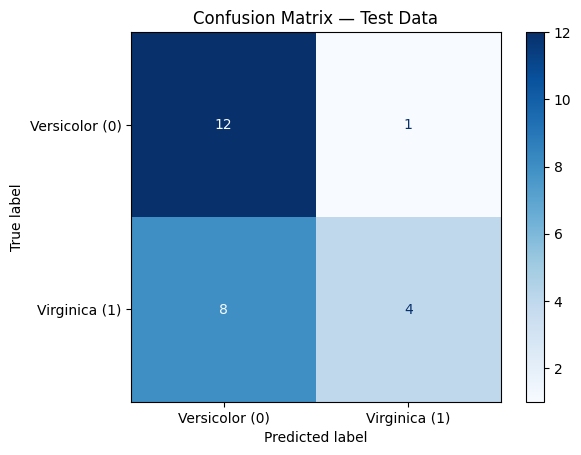

Accuracy:  0.640
Precision: 0.800
Recall:    0.333
F1 Score:  0.471
ROC-AUC:   0.667
Log Loss:  0.707

Classification Report:
              precision    recall  f1-score   support

  Versicolor       0.60      0.92      0.73        13
   Virginica       0.80      0.33      0.47        12

    accuracy                           0.64        25
   macro avg       0.70      0.63      0.60        25
weighted avg       0.70      0.64      0.60        25



In [16]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Versicolor (0)", "Virginica (1)"]
).plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix — Test Data")
plt.show()

print(f"Accuracy:  {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision: {precision_score(y_test, y_pred):.3f}")
print(f"Recall:    {recall_score(y_test, y_pred):.3f}")
print(f"F1 Score:  {f1_score(y_test, y_pred):.3f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob):.3f}")
print(f"Log Loss:  {log_loss(y_test, y_prob):.3f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=["Versicolor", "Virginica"]))

### ROC curve (optional evaluation visual)

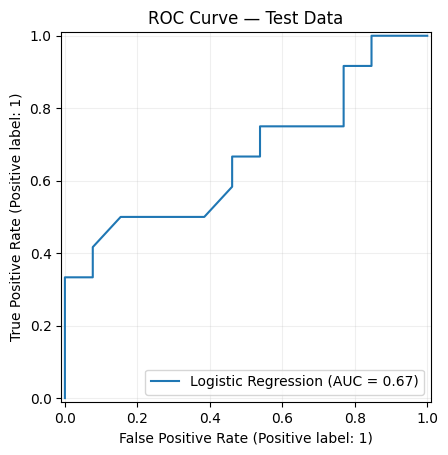

In [17]:
RocCurveDisplay.from_predictions(y_test, y_prob, name="Logistic Regression")
plt.title("ROC Curve — Test Data")
plt.grid(alpha=0.2)
plt.show()

## 14. Cross-validation — evaluate more reliably on training data

A single train/test split can be influenced by which rows go into each set.

**5-fold cross-validation** splits the training set into five parts. Each part serves as validation data once, while the other four are used for training.

We cross-validate **the entire pipeline**, so scaling is learned separately within each fold. The **held-out test set is not used** here.

In [18]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(
    model, X_train, y_train, cv=cv, scoring="f1"
)

print("F1 score in each fold:", np.round(cv_scores, 3))
print(f"Mean CV F1: {cv_scores.mean():.3f}")
print(f"Std CV F1:  {cv_scores.std():.3f}")

F1 score in each fold: [0.8   0.714 0.706 0.706 0.571]
Mean CV F1: 0.699
Std CV F1:  0.073


## 15. Hyperparameter tuning using GridSearchCV

`GridSearchCV` tries a list of hyperparameter values and evaluates each using cross-validation.

Here we tune `C`, which controls how strongly Logistic Regression penalizes large coefficients:

- **Smaller C:** stronger regularization.
- **Larger C:** weaker regularization.

We'll choose the `C` with the highest **mean cross-validation F1 score** on the training data.

> `logreg__C` means: choose the parameter `C` inside the pipeline step named `logreg`.

In [19]:
param_grid = {
    "logreg__C": [0.01, 0.1, 1, 10, 100]
}

grid = GridSearchCV(
    estimator=Pipeline([
        ("scaler", StandardScaler()),
        ("logreg", LogisticRegression(max_iter=1000))
    ]),
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=1,  # run sequentially; student-laptop friendly
    refit=True
)

grid.fit(X_train, y_train)
print("Best C:", grid.best_params_["logreg__C"])
print(f"Best mean CV F1: {grid.best_score_:.3f}")

cv_results = pd.DataFrame({
    "C": grid.cv_results_["param_logreg__C"],
    "Mean CV F1": grid.cv_results_["mean_test_score"],
    "Std CV F1": grid.cv_results_["std_test_score"]
})
display(cv_results.sort_values("Mean CV F1", ascending=False))

Best C: 0.01
Best mean CV F1: 0.727


,C,Mean CV F1,Std CV F1
0,0.010,0.727,0.045
4,100.000,0.719,0.044
3,10.000,0.719,0.044
2,1.000,0.699,0.073
1,0.100,0.683,0.079


## 16. Final comparison on the test set

The test set was not used to select `C`. Now evaluate the tuned model on that held-out test set and compare it with the original model.

**Note:** GridSearchCV may or may not improve the test score. That is normal; it chooses a parameter based on cross-validation results, not guaranteed test-set performance.

In [20]:
best_model = grid.best_estimator_
tuned_pred = best_model.predict(X_test)
tuned_prob = best_model.predict_proba(X_test)[:, 1]

comparison_metrics = pd.DataFrame({
    "Model": ["Original", "Tuned"],
    "Test Accuracy": [accuracy_score(y_test, y_pred), accuracy_score(y_test, tuned_pred)],
    "Test Precision": [precision_score(y_test, y_pred), precision_score(y_test, tuned_pred)],
    "Test Recall": [recall_score(y_test, y_pred), recall_score(y_test, tuned_pred)],
    "Test F1": [f1_score(y_test, y_pred), f1_score(y_test, tuned_pred)],
    "Test ROC-AUC": [roc_auc_score(y_test, y_prob), roc_auc_score(y_test, tuned_prob)]
})
display(comparison_metrics)

,Model,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC
0,Original,0.640,0.800,0.333,0.471,0.667
1,Tuned,0.640,0.714,0.417,0.526,0.628


## 17. Optional: Understand the classification threshold

The probability estimated by a trained model remains the same, but changing the **classification threshold** can change the predicted labels.

We show 0.3, 0.5, and 0.7 for learning purposes only. **Do not use the final test results to choose the best threshold**; threshold selection should use validation data.

In [21]:
threshold_rows = []
for t in [0.3, 0.5, 0.7]:
    predicted = (tuned_prob >= t).astype(int)
    threshold_rows.append({
        "Threshold": t,
        "Predicted class-1 count": int(predicted.sum()),
        "Precision": precision_score(y_test, predicted, zero_division=0),
        "Recall": recall_score(y_test, predicted, zero_division=0),
        "F1": f1_score(y_test, predicted, zero_division=0)
    })
display(pd.DataFrame(threshold_rows))

,Threshold,Predicted class-1 count,Precision,Recall,F1
0,0.300,25,0.480,1.000,0.649
1,0.500,7,0.714,0.417,0.526
2,0.700,0,0.000,0.000,0.000


---
## 18. Student practice activities

Complete these after running the notebook.

**Activity 1 — Manual calculation**

Using the illustrative Pass/Fail model `z = 1.5x − 6`:
- Calculate `z` for a student who studied **3.5 hours**.
- Apply Sigmoid and print the predicted probability.
- Predict Pass/Fail using a threshold of 0.5.

**Activity 2 — Evaluation**

Change the train/test split to `test_size=0.30` while keeping `stratify=y` and `random_state=42`. Retrain and compare Accuracy, Precision, Recall, and F1. Explain why the values can change.

**Activity 3 — GridSearchCV**

Expand the `C` values to `[0.001, 0.01, 0.1, 1, 10, 100, 1000]`. Which value gives the highest mean cross-validation F1 score?

**Activity 4 — Features**

Replace `sepal length (cm)` and `sepal width (cm)` with `petal length (cm)` and `petal width (cm)`, rerun the model, and compare F1 and the decision boundary. You can create the new dataframe from `iris.frame` using the same class filter.

**Questions for discussion**

1. Why is the output of Sigmoid suitable as a class probability?
2. What is the difference between `predict()` and `predict_proba()`?
3. Why do we fit feature scaling only on training data?
4. Why do we use cross-validation when tuning `C`?
5. Why should we not use the held-out test set to pick a threshold or hyperparameter?

In [22]:
# Activity 1 starter — uncomment and complete the TODOs.
# x_new = 3.5
# z_new = 1.5 * x_new - 6
# p_new = sigmoid(z_new)
# predicted_new = int(p_new >= 0.5)
# print(z_new, p_new, predicted_new)

## Quick recap

| Concept | Key idea |
|---|---|
| Linear score | `z = mx + c` |
| Sigmoid | Converts the score into a probability between 0 and 1 |
| Threshold | Converts probability into a predicted class |
| Log Loss | Penalizes predicted probabilities that disagree with actual classes |
| Model training | Learns coefficients by repeatedly reducing an objective |
| `fit()` | Trains the pipeline using features and actual class labels |
| `predict_proba()` | Returns probability estimates for each class |
| `predict()` | Returns class labels |
| Cross-validation | Estimates performance over several training/validation partitions |
| GridSearchCV | Selects hyperparameters using cross-validation |

**Main takeaway:** Logistic Regression learns coefficients, calculates a linear score, converts it to a probability with Sigmoid, then applies a threshold to predict the class.